Accuracy : 0.9736842105263158
Precision: 1.0
Recall   : 0.9285714285714286
F1       : 0.9629629629629629
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



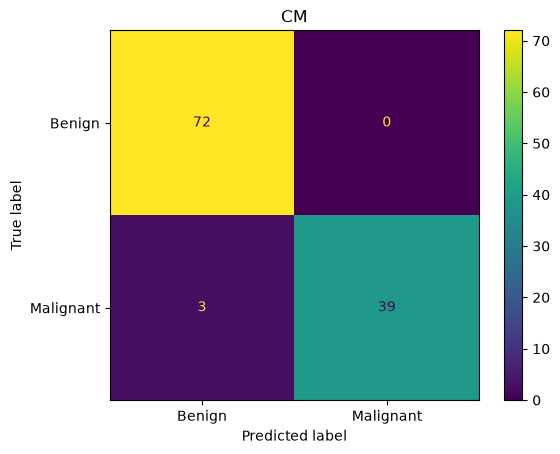

In [1]:
# ===================== REVISION / ONE-SHOT: METRICS FOR CLASSIFIERS =====================
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

# 1) Load + clean + encode
df = pd.read_csv("datasets/Breast Cancer.csv").drop(["id", "Unnamed: 32"], axis=1)
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"].map({"M": 1, "B": 0})            # positive class = malignant

# 2) Stratified split (keeps imbalance ratio in train and test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3) Model (class_weight="balanced" helps the minority class)
model = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42).fit(X_train, y_train)
y_pred = model.predict(X_test)

# 4) Metrics (binary: default average; multi-class: average=None per class or "macro")
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1       :", f1_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Benign", "Malignant"]); plt.title("CM"); plt.show()

# 5) kNN needs scaling: sc = StandardScaler(); X_train = sc.fit_transform(X_train); X_test = sc.transform(X_test)

# ---------------- VIVA NOTES ----------------
# Precision = TP / (TP + FP): of predicted positives, how many are right.
# Recall = TP / (TP + FN): of real positives, how many were found (key for cancer: avoid missed tumours).
# F1 = 2PR / (P + R): balance of precision and recall, good for imbalanced data.
# Accuracy is misleading on imbalanced data (predicting all "benign" still scores ~63%).
# Macro avg = plain mean over classes; weighted avg = weighted by class support.
# kNN: k neighbours vote, distance based -> scale features; small k overfits, large k underfits.

### Q31

Use the Breast Cancer dataset to train a random forest classifier. The model will be trained to accurately classify tumors as benign or malignant. The dataset is imbalanced, with a significant majority of benign samples. Evaluate the model's performance using accuracy, precision, recall, and F1-score. generate complete problem statement

**Problem Statement**

A hospital wants an automated system that helps doctors decide whether a breast tumour is **benign (B)** or **malignant (M)**, based on measurements taken from a digitized image of a fine needle aspirate (FNA).

**Dataset:** `Breast Cancer.csv` (Wisconsin Diagnostic Breast Cancer), with 569 samples.
- `id`: patient ID (not a feature).
- `diagnosis`: target, M = malignant, B = benign.
- 30 numeric features: the mean, standard error and worst value of 10 cell nucleus properties (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension).
- `Unnamed: 32`: an empty column that must be dropped.
- The data is imbalanced: 357 benign (about 63%) vs 212 malignant (about 37%).

**Tasks**
1. Load the data, remove the `id` and empty columns, check for missing values and the class distribution.
2. Encode the target (M = 1, B = 0). Malignant is the positive class.
3. Split into 80% training and 20% testing data, stratified so that both parts keep the class imbalance.
4. Train a Random Forest classifier, handling the imbalance with `class_weight="balanced"`.
5. Predict on the test set and report accuracy, precision, recall and F1-score, plus the classification report and confusion matrix.
6. Explain why accuracy alone is not enough for imbalanced medical data, and why recall for malignant tumours matters most (a missed cancer is worse than a false alarm).
7. Show the most important features.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

In [3]:
# Load and clean
df = pd.read_csv("datasets/Breast Cancer.csv")
df = df.drop(["id", "Unnamed: 32"], axis=1)
print(df.shape)
print("Missing values:", df.isnull().sum().sum())
print(df["diagnosis"].value_counts())

(569, 31)
Missing values: 0
diagnosis
B    357
M    212
Name: count, dtype: int64


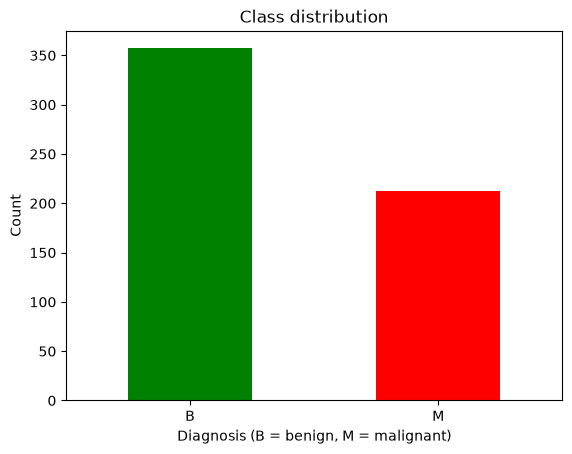

In [4]:
# Class distribution (imbalance)
df["diagnosis"].value_counts().plot(kind="bar", color=["green", "red"])
plt.title("Class distribution")
plt.xlabel("Diagnosis (B = benign, M = malignant)")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

In [5]:
# Encode target, stratified split
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"].map({"M": 1, "B": 0})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (455, 30) | Test: (114, 30)


In [6]:
# Random forest with balanced class weights
model = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [7]:
# Metrics (positive class = malignant)
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))

Accuracy : 0.9737
Precision: 1.0
Recall   : 0.9286
F1-score : 0.963
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



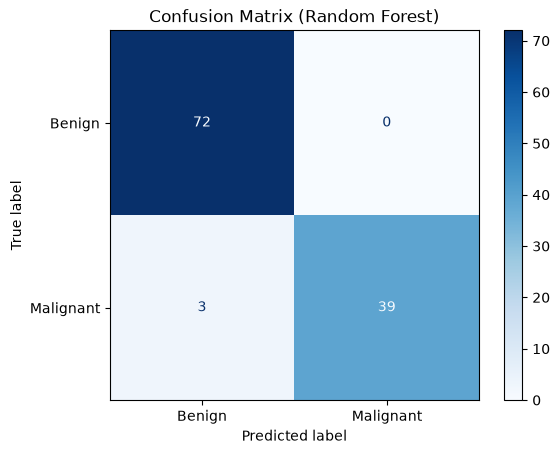

In [8]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Benign", "Malignant"], cmap="Blues")
plt.title("Confusion Matrix (Random Forest)")
plt.show()

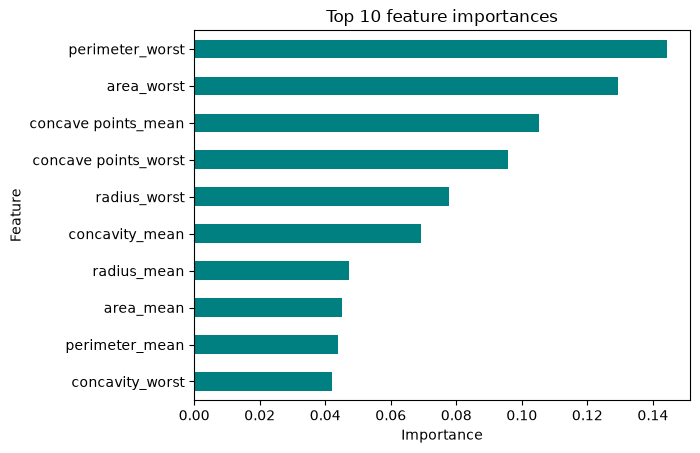

In [9]:
# Top 10 important features
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values().tail(10)
imp.plot(kind="barh", color="teal")
plt.title("Top 10 feature importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

### Q32

Use the Wine dataset, to develop a k-nearest neighbors (k-NN) classifier to classify different types of wine based on their chemical properties. You will evaluate the model's performance using various metrics, including accuracy, precision, recall, and F1-score.
- Load the Wine dataset from a CSV file
- checking for missing values, understanding the distribution of classes, and visualizing the features.
- Normalize or standardize the features if necessary to improve the performance of the k-NN classifier
- split the dataset into training and testing sets (e.g., 80% training and 20% testing)
- Train the classifier on the training dataset.
- Use the trained model to make predictions on the test dataset.
- Calculate and print the following performance metrics:
  - Accuracy
  - Precision (for each class)
  - Recall (for each class)
  - F1-score (for each class)

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

In [11]:
# Load CSV ('Wine' column = class 1, 2, 3)
df = pd.read_csv("datasets/wine.csv")
print(df.shape)
print(df.head())

(178, 14)
   Wine  Alcohol  Malic.acid   Ash   Acl   Mg  Phenols  Flavanoids  \
0     1    14.23        1.71  2.43  15.6  127     2.80        3.06   
1     1    13.20        1.78  2.14  11.2  100     2.65        2.76   
2     1    13.16        2.36  2.67  18.6  101     2.80        3.24   
3     1    14.37        1.95  2.50  16.8  113     3.85        3.49   
4     1    13.24        2.59  2.87  21.0  118     2.80        2.69   

   Nonflavanoid.phenols  Proanth  Color.int   Hue    OD  Proline  
0                  0.28     2.29       5.64  1.04  3.92     1065  
1                  0.26     1.28       4.38  1.05  3.40     1050  
2                  0.30     2.81       5.68  1.03  3.17     1185  
3                  0.24     2.18       7.80  0.86  3.45     1480  
4                  0.39     1.82       4.32  1.04  2.93      735  


Missing values per column:
Wine                    0
Alcohol                 0
Malic.acid              0
Ash                     0
Acl                     0
Mg                      0
Phenols                 0
Flavanoids              0
Nonflavanoid.phenols    0
Proanth                 0
Color.int               0
Hue                     0
OD                      0
Proline                 0
dtype: int64
Wine
1    59
2    71
3    48
Name: count, dtype: int64


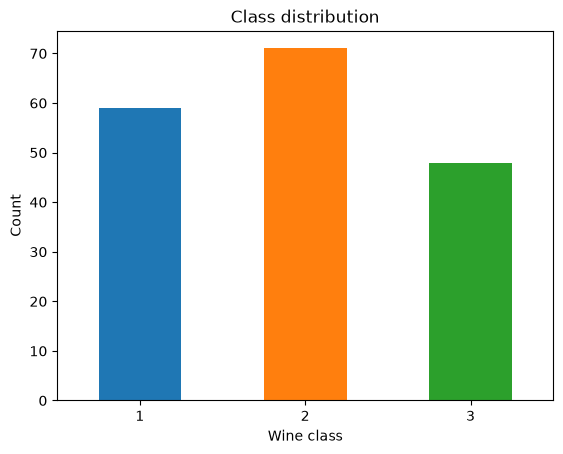

In [12]:
# Missing values and class distribution
print("Missing values per column:")
print(df.isnull().sum())
print(df["Wine"].value_counts().sort_index())
df["Wine"].value_counts().sort_index().plot(kind="bar", color=["tab:blue", "tab:orange", "tab:green"])
plt.title("Class distribution")
plt.xlabel("Wine class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

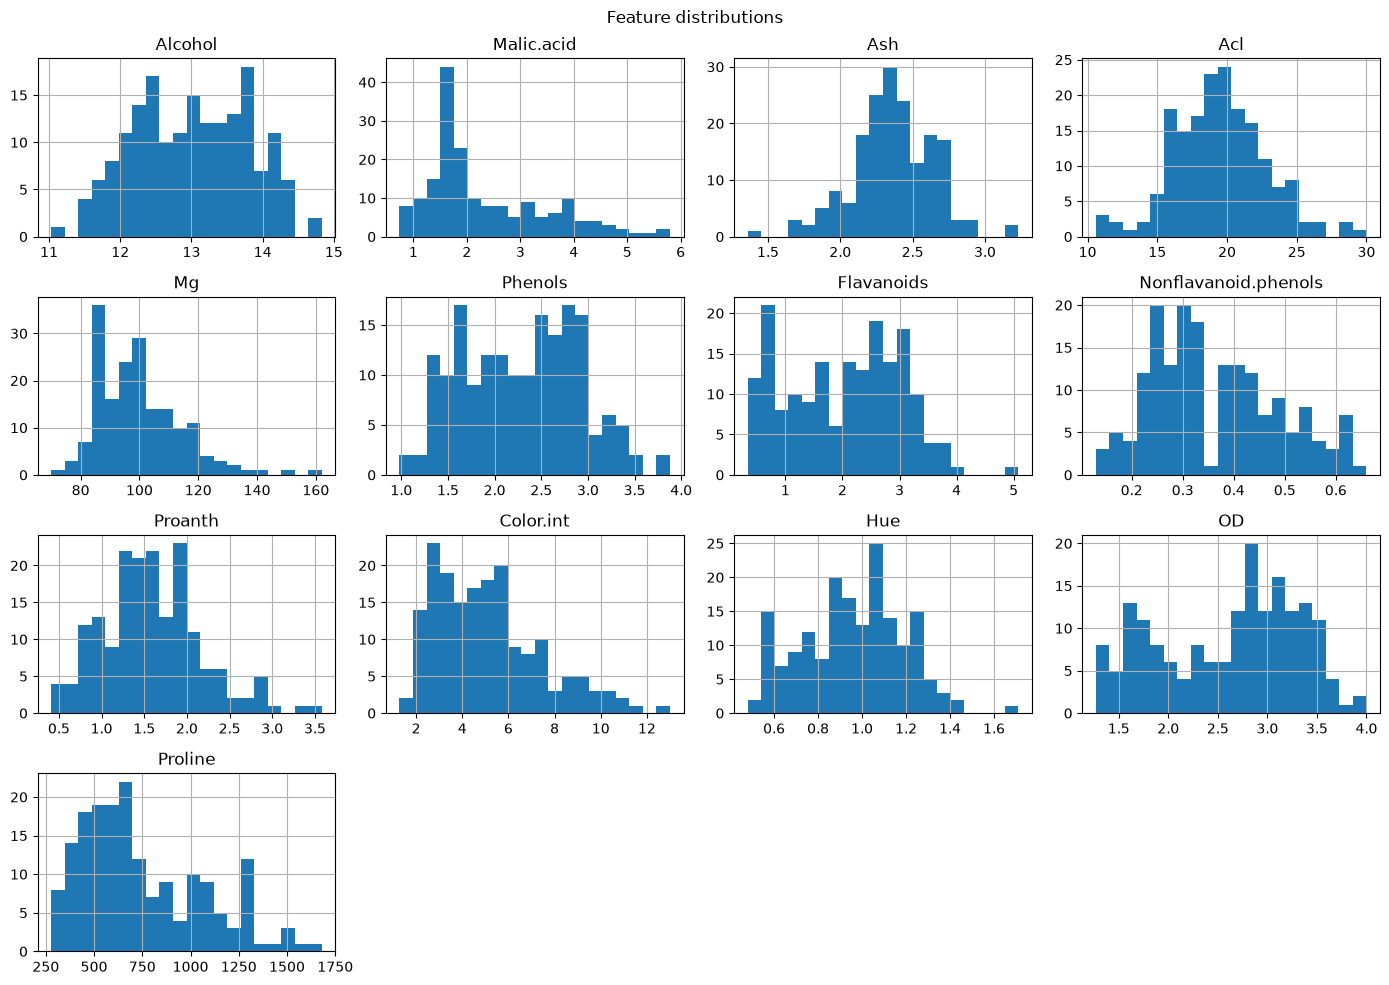

In [13]:
# Visualize features: histograms show very different scales (Proline in 1000s, Hue around 1)
df.drop("Wine", axis=1).hist(figsize=(14, 10), bins=20)
plt.suptitle("Feature distributions")
plt.tight_layout()
plt.show()

In [14]:
# Split 80/20, then standardize (kNN uses distances)
X = df.drop("Wine", axis=1)
y = df["Wine"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [15]:
# Train kNN and predict
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [16]:
# Metrics (average=None gives one value per class)
classes = sorted(y.unique())
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
metrics = pd.DataFrame({
    "Precision": precision_score(y_test, y_pred, average=None),
    "Recall": recall_score(y_test, y_pred, average=None),
    "F1-score": f1_score(y_test, y_pred, average=None),
}, index=[f"Class {c}" for c in classes])
print(metrics.round(3))
print(classification_report(y_test, y_pred))

Accuracy: 0.9722
         Precision  Recall  F1-score
Class 1      1.000   1.000     1.000
Class 2      1.000   0.929     0.963
Class 3      0.909   1.000     0.952
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      0.93      0.96        14
           3       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



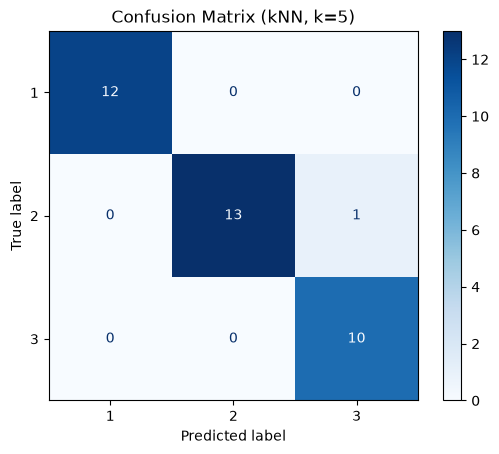

In [17]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Confusion Matrix (kNN, k=5)")
plt.show()